In [1]:
import numpy as np

In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [5]:
wholesale = pd.read_csv(r"C:\Users\chara\OneDrive\Desktop\simple calculator\ML\Wholesale customers data.csv")

In [6]:
wholesale.shape

(440, 8)

In [7]:
wholesale

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185
...,...,...,...,...,...,...,...,...
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125


In [37]:
wholesale.head(20)

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185
5,2,3,9413,8259,5126,666,1795,1451
6,2,3,12126,3199,6975,480,3140,545
7,2,3,7579,4956,9426,1669,3321,2566
8,1,3,5963,3648,6192,425,1716,750
9,2,3,6006,11093,18881,1159,7425,2098


In [9]:
wholesale.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [10]:
wholesale["Channel"]

0      2
1      2
2      2
3      1
4      2
      ..
435    1
436    1
437    2
438    1
439    1
Name: Channel, Length: 440, dtype: int64

In [11]:
wholesale["Region"]

0      3
1      3
2      3
3      3
4      3
      ..
435    3
436    3
437    3
438    3
439    3
Name: Region, Length: 440, dtype: int64

In [12]:
wholesale["Channel"].isnull().sum()

np.int64(0)

In [13]:
wholesale["Region"].isnull().sum()

np.int64(0)

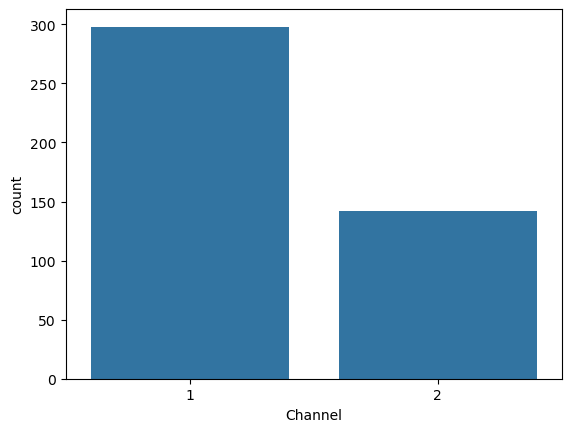

In [14]:
sns.countplot(data=wholesale, x="Channel")
plt.show()

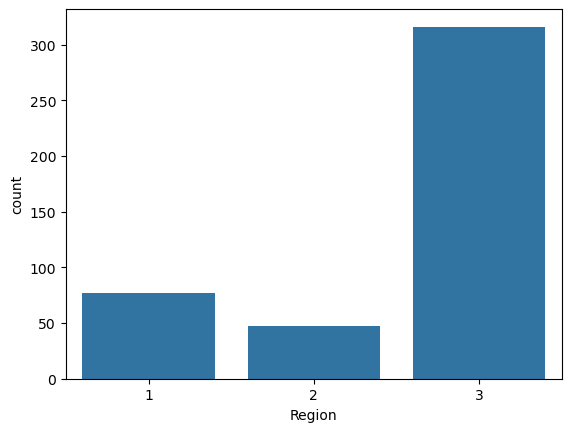

In [15]:
sns.countplot(data=wholesale, x="Region")
plt.show()

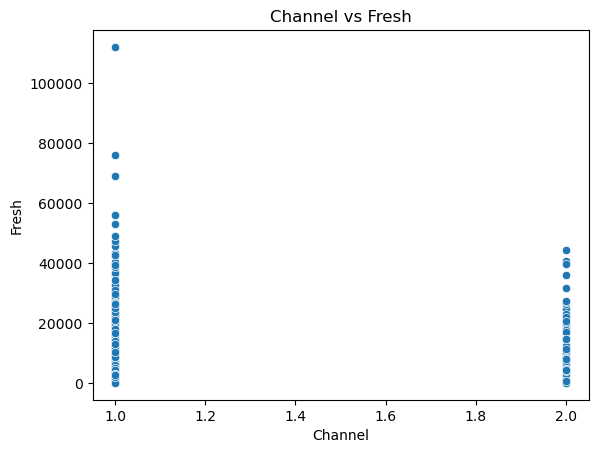

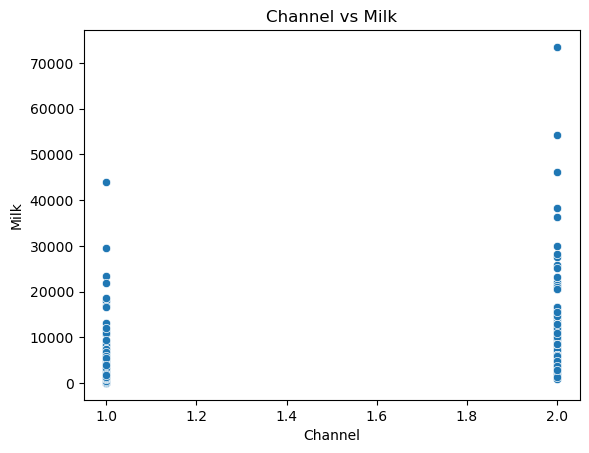

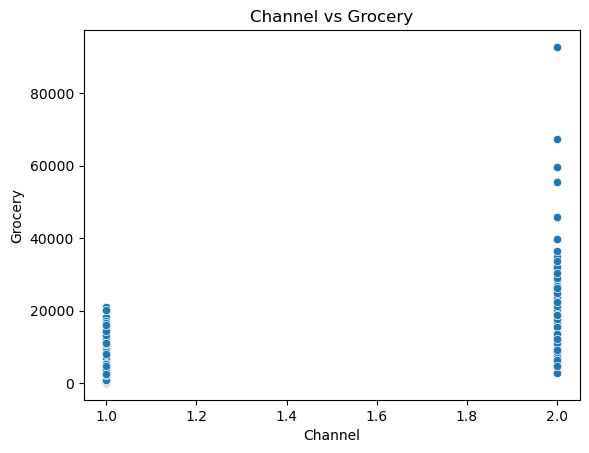

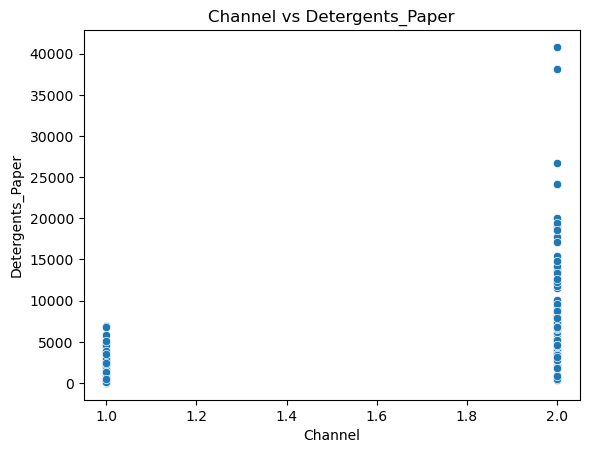

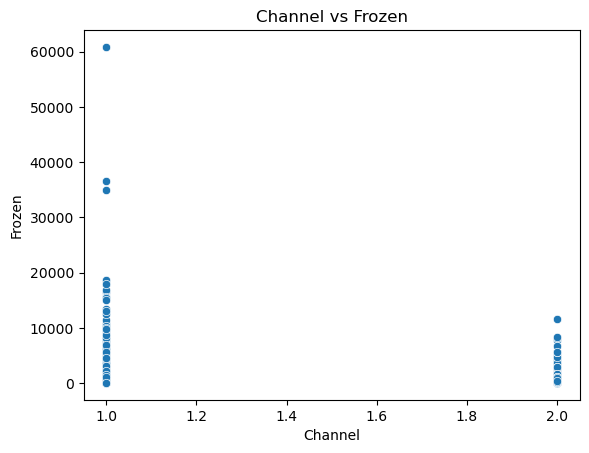

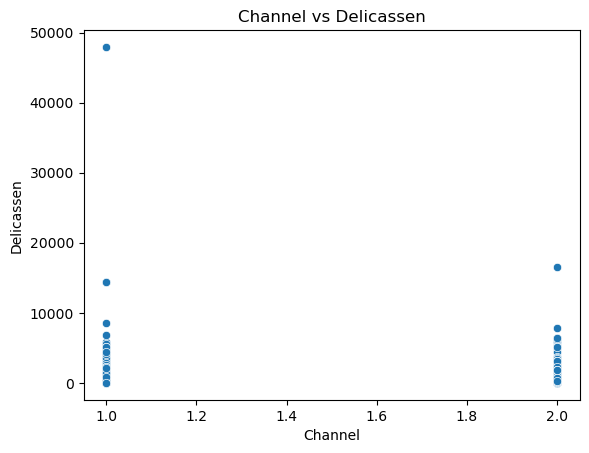

In [16]:
columns = ["Fresh", "Milk", "Grocery", "Detergents_Paper",
           "Frozen", "Delicassen"]

for i in columns:
    sns.scatterplot(data=wholesale, x="Channel", y=i)
    plt.title(f"Channel vs {i}")
    plt.show()

In [17]:
wholesale.isnull().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

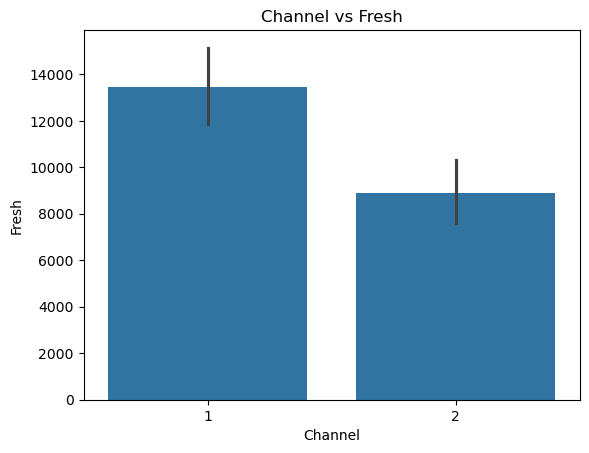

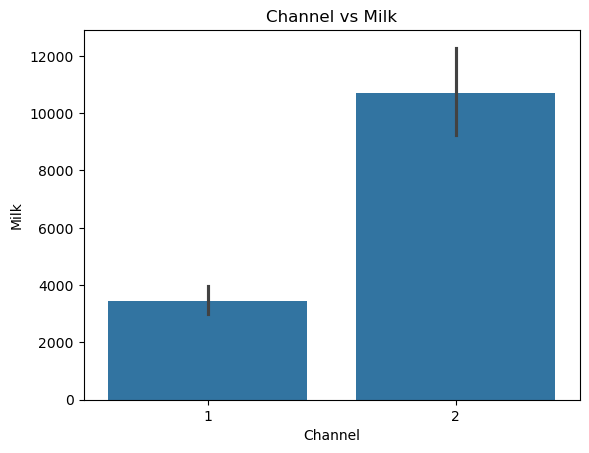

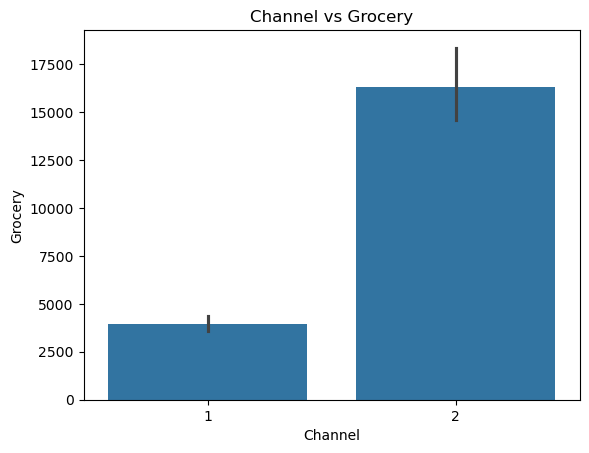

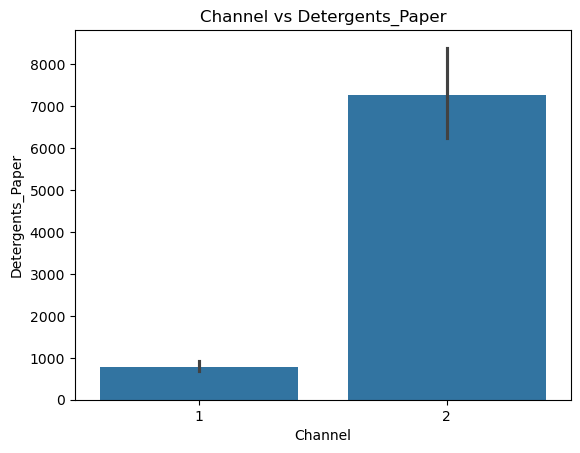

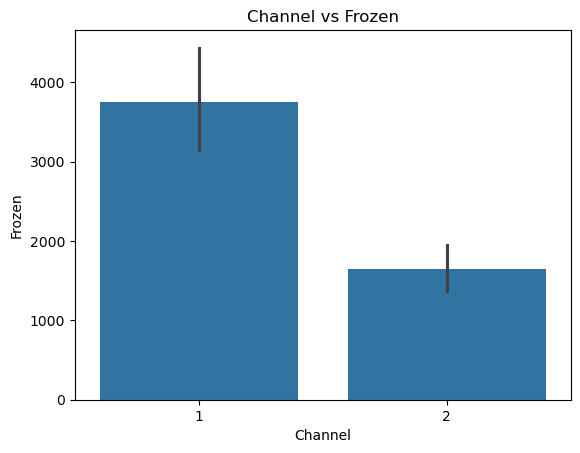

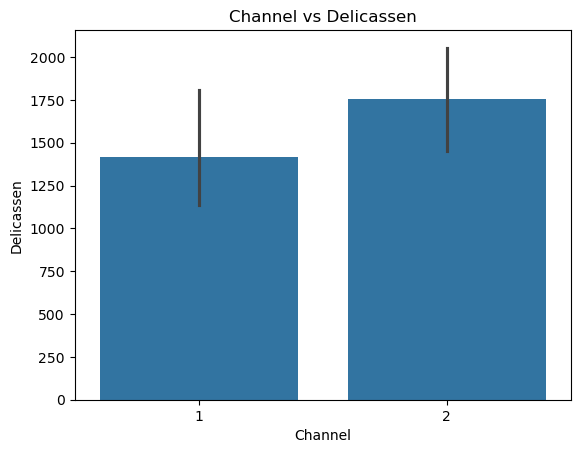

In [18]:
columns = ["Fresh", "Milk", "Grocery", "Detergents_Paper",
           "Frozen", "Delicassen"]

for i in columns:
    sns.barplot(data=wholesale, x="Channel", y=i)
    plt.title(f"Channel vs {i}")
    plt.show()

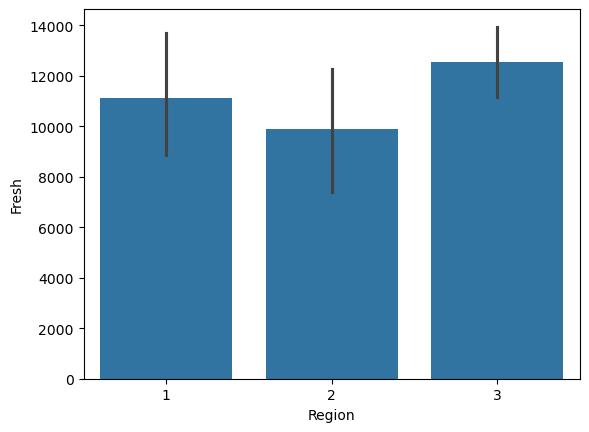

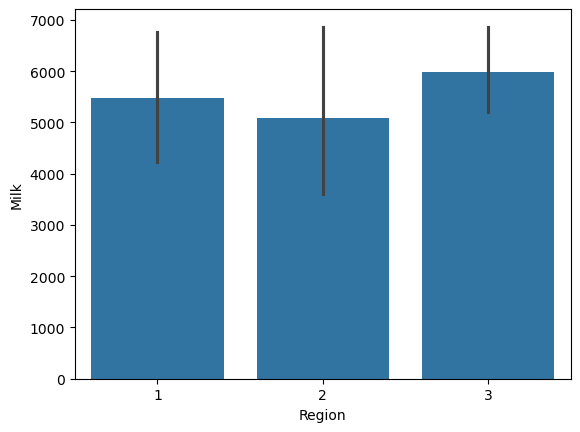

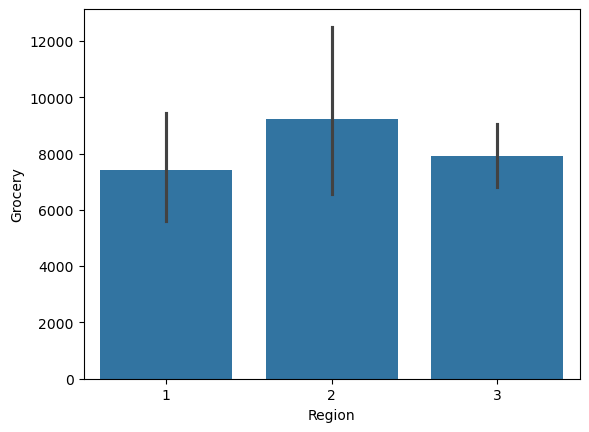

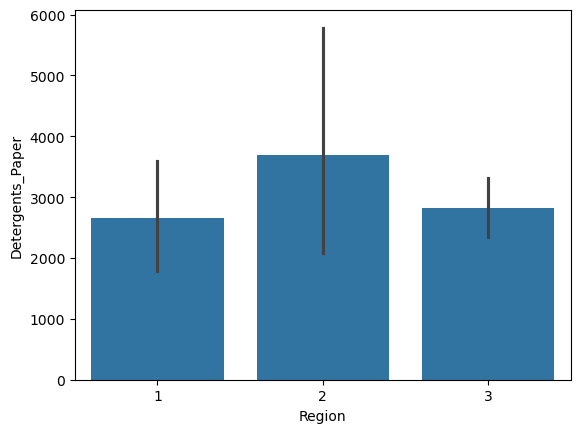

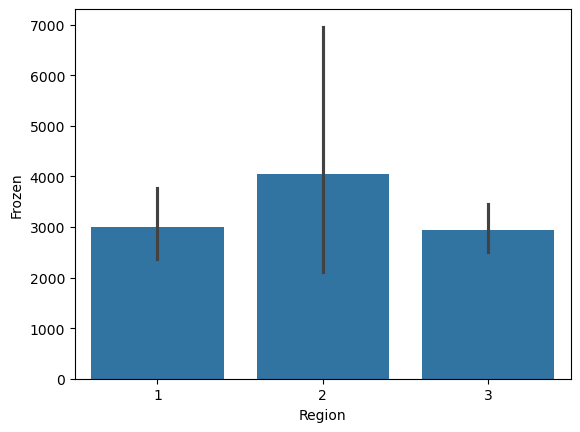

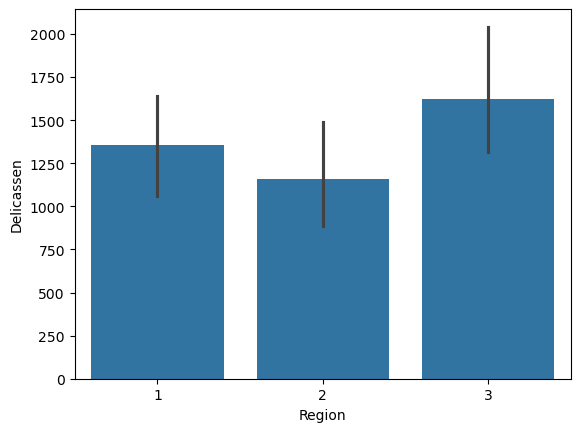

In [19]:
for i in columns:
    sns.barplot(data=wholesale,x="Region",y=i)
    plt.show()

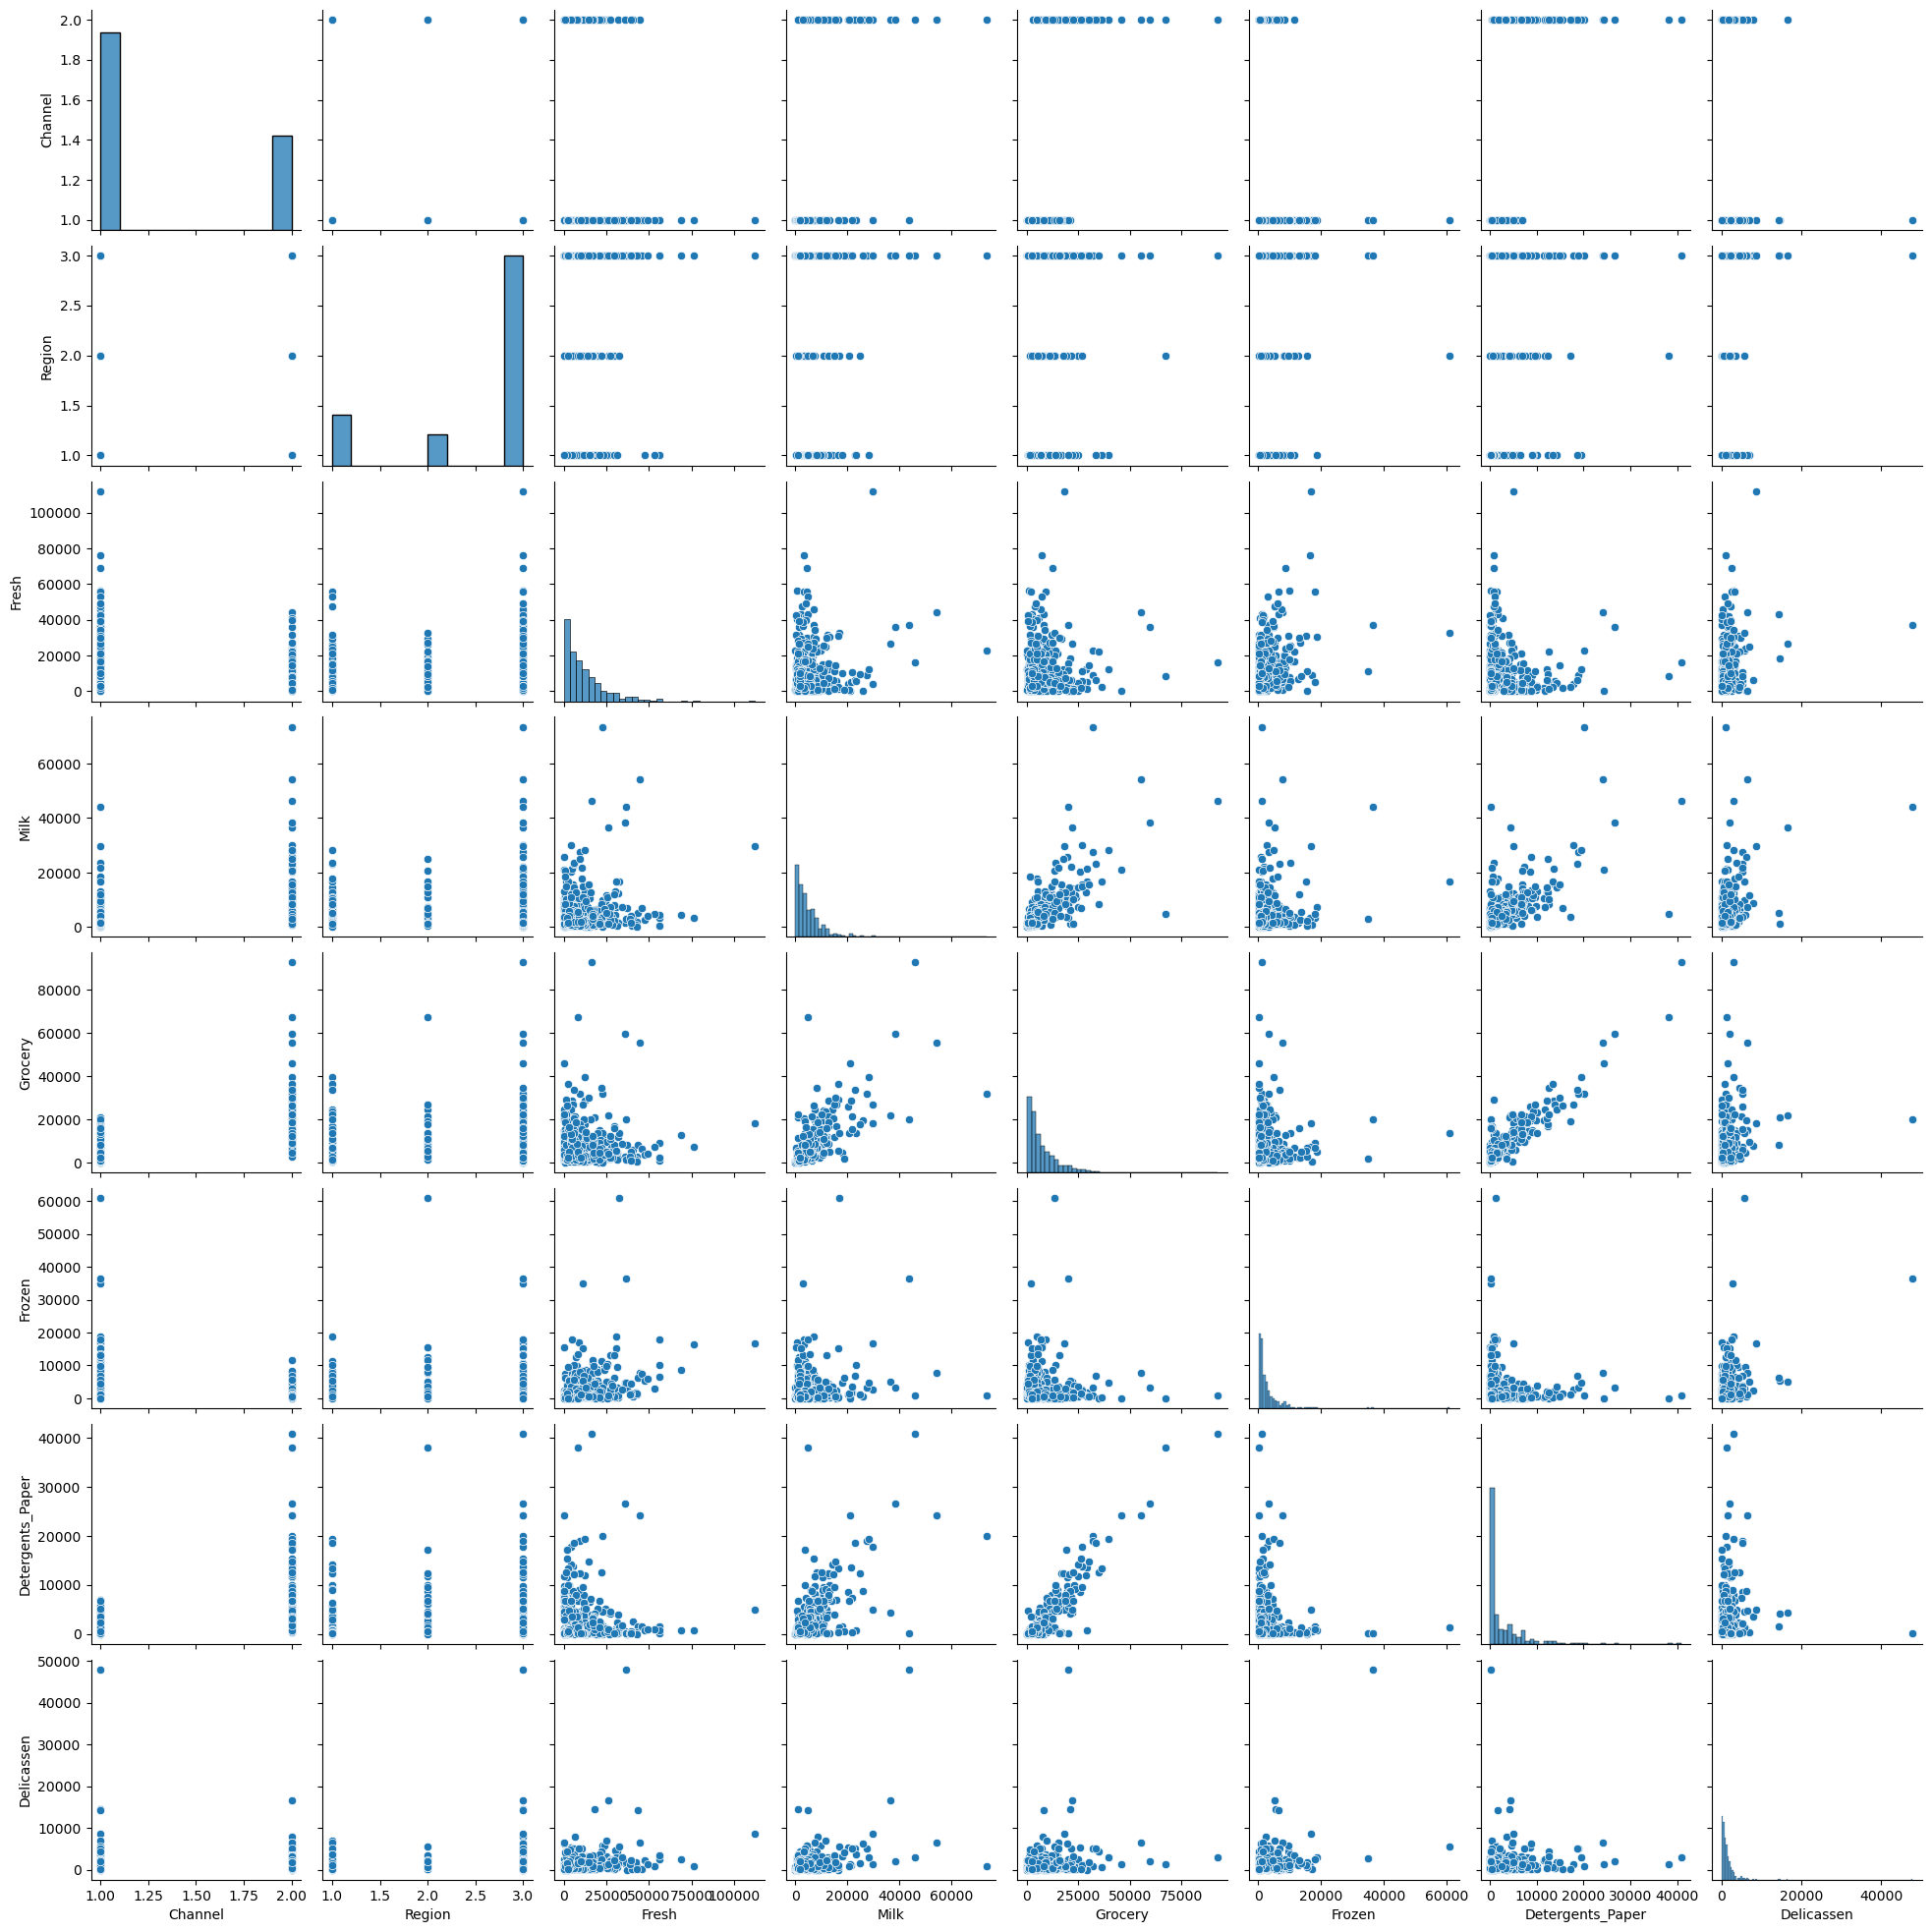

In [20]:
sns.pairplot(data=wholesale)
plt.show()

In [21]:
pd.crosstab(wholesale['Region'],wholesale['Channel'])

Channel,1,2
Region,,
1,59,18
2,28,19
3,211,105


In [22]:
from sklearn.linear_model import LogisticRegression

In [23]:
from sklearn.model_selection import train_test_split

In [24]:
X = wholesale[["Fresh", "Milk", "Grocery",
               "Detergents_Paper", "Frozen", "Delicassen"]]

y = wholesale["Channel"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [25]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [26]:
y_pred = model.predict(X_test)
print(y_pred)

[1 2 1 2 1 2 2 1 1 1 2 1 1 2 1 2 1 1 1 1 1 1 1 1 1 1 1 1 2 2 1 2 2 1 1 1 2
 1 1 2 1 1 1 2 1 1 2 1 1 1 1 1 2 1 1 1 2 1 2 1 2 1 2 1 2 1 1 1 1 1 1 1 1 1
 2 1 2 2 1 2 1 1 1 1 1 2 1 1]


In [27]:
result = pd.DataFrame({
    "Actual Channel":y_test,
    "Predicted Channel":y_pred
})
print(result.head(10))

     Actual Channel  Predicted Channel
281               2                  1
426               1                  2
6                 2                  1
82                2                  2
103               1                  1
61                2                  2
268               2                  2
254               1                  1
403               1                  1
113               1                  1


In [28]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")

Accuracy: 0.9090909090909091
Accuracy percentage: 90.9090909090909 %


In [29]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.92      0.95      0.93        60
           2       0.88      0.82      0.85        28

    accuracy                           0.91        88
   macro avg       0.90      0.89      0.89        88
weighted avg       0.91      0.91      0.91        88



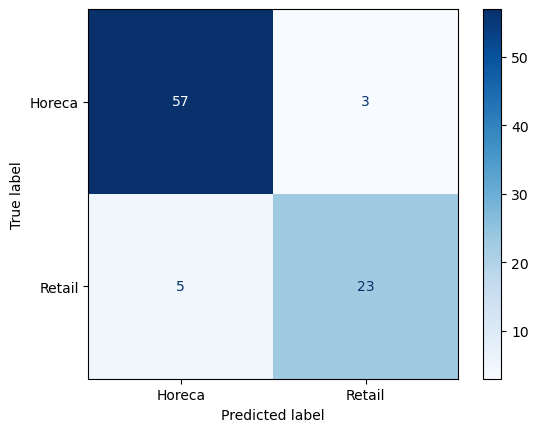

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Horeca', 'Retail']
)

display.plot(cmap='Blues')
plt.show()

In [31]:
from sklearn.model_selection import train_test_split
a = wholesale[[
    "Fresh", "Milk", "Grocery",
    "Detergents_Paper", "Frozen", "Delicassen"]]
b = wholesale["Region"]
a_train, a_test, b_train, b_test = train_test_split(
    a, b,
    test_size=0.2,
    random_state=42,
    stratify=b
)


In [32]:
print("a_train:", a_train.shape)
print("b_train:", b_train.shape)

print("a_test:", a_test.shape)
print("b_test:", b_test.shape)

print(b_train.value_counts())

a_train: (352, 6)
b_train: (352,)
a_test: (88, 6)
b_test: (88,)
Region
3    253
1     61
2     38
Name: count, dtype: int64


In [33]:
model = LogisticRegression(max_iter=1000)

model.fit(a_train, b_train)

C:\Users\chara\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [34]:
b_pred = model.predict(a_test)
print(b_pred)

[3 3 3 3 3 3 3 3 3 3 3 3 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 2 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3]


In [35]:
result = pd.DataFrame({
    "Actual Channel":b_test,
    "Predicted Channel":b_pred
})
print(result.head(10))

     Actual Channel  Predicted Channel
62                3                  3
357               3                  3
321               2                  3
169               3                  3
318               2                  3
399               3                  3
406               3                  3
41                3                  3
407               3                  3
95                3                  3


In [38]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(b_test, b_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")

Accuracy: 0.6931818181818182
Accuracy percentage: 69.31818181818183 %


In [41]:
print("Actual Region:", b_test.iloc[50])
print("Predicted Region:", b_pred[50])

print("Actual Channel:", y_test.iloc[50])
print("Predicted Channel:", y_pred[50])

Actual Region: 3
Predicted Region: 3
Actual Channel: 1
Predicted Channel: 1
